In [ ]:
from pathlib import Path
import os
import time
import sys

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers

# ============================================================
# ALPHAGENOME API KEY
# ============================================================

API_KEY = ""  # Paste your key between the quotes

# ============================================================
# PATHS
# ============================================================

# Relative to the notebooks/ directory
BASE = Path("../data/lung_hic_alphagenome")

AG_DIR = BASE / "alphagenome_analysis"

LOOP_FILE = BASE / (
    "189_clean_genes_final_candidate_loops."
    "regulatory_direction_fixed."
    "with_diffHiC_label_fuzzy30kb.bedpe"
)

UCSC_FILE = AG_DIR / "SNP_input_alphagenome.tsv"

# Temporary rerun directory
OUT = AG_DIR / "temporary_rerun"
OUT.mkdir(parents=True, exist_ok=True)

PAIR_FILE = OUT / "139_distal_loop_SNP_gene_pairs.tsv"
VARIANT_FILE = OUT / "alphagenome_variant_input.clean.tsv"
SCORE_FILE = OUT / "alphagenome_RNA_target_gene_scores.tsv"
STATUS_FILE = OUT / "alphagenome_status.tsv"
LUNG_FILE = OUT / "alphagenome_RNA_target_gene_scores_LUNG.tsv"

# ============================================================
# CHECK INPUT FILES
# ============================================================

for name, path in {
    "Hi-C loops": LOOP_FILE,
    "UCSC dbSNP": UCSC_FILE
}.items():
    print(name, path.exists(), path)
    assert path.exists(), f"Missing: {path}"

# ============================================================
# INITIALIZE ALPHAGENOME
# ============================================================

assert API_KEY != "YOUR_API_KEY_HERE", "Please enter your API key"

model = dna_client.create(api_key=API_KEY)

metadata = model.output_metadata(
    dna_client.Organism.HOMO_SAPIENS
)

rna_scorer = variant_scorers.RECOMMENDED_VARIANT_SCORERS["RNA_SEQ"]

print("\nPython:", sys.executable)
print("AlphaGenome initialized successfully!")
print("Output directory:", OUT)

In [26]:
# ============================================================
# BLOCK 2 — PREPARE SNP–GENE PAIRS AND REF/ALT VARIANTS
# ============================================================

# ------------------------------------------------------------
# 1. Load Hi-C loops
# ------------------------------------------------------------

loops = pd.read_csv(
    LOOP_FILE,
    sep="\t",
    dtype=str
).fillna("")

print("Total input loops:", len(loops))

bool_cols = [
    "a1_has_snp", "a2_has_snp",
    "a1_has_enh", "a2_has_enh",
    "a1_has_tss", "a2_has_tss",
    "a1_has_snp_enh", "a2_has_snp_enh"
]

for c in bool_cols:
    loops[c] = (
        loops[c]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False})
    )

    assert loops[c].notna().all(), f"Invalid values in {c}"


# ------------------------------------------------------------
# 2. Verify SNP + enhancer annotations
# ------------------------------------------------------------

for anchor in [1, 2]:

    expected_flag = (
        loops[f"a{anchor}_has_snp"] &
        loops[f"a{anchor}_has_enh"]
    )

    observed_flag = loops[f"a{anchor}_has_snp_enh"]

    n_mismatch = (expected_flag != observed_flag).sum()

    print(
        f"Anchor {anchor} SNP/enhancer flag mismatches:",
        n_mismatch
    )

    assert n_mismatch == 0, (
        f"Unexpected SNP/enhancer annotations in anchor {anchor}"
    )


# ------------------------------------------------------------
# 3. Extract SNP–gene relationships
# ------------------------------------------------------------

def split_items(x):
    if pd.isna(x):
        return []

    return [
        v.strip()
        for v in str(x).split(",")
        if v.strip()
    ]


records = []

for _, r in loops.iterrows():

    directions = [
        (
            "a1_has_snp_enh",
            "a2_has_tss",
            "anchor1_LD_snps",
            "anchor2_TSS_hits_10kb",
            "chr1",
            "chr2",
            "anchor1",
            "anchor2"
        ),
        (
            "a2_has_snp_enh",
            "a1_has_tss",
            "anchor2_LD_snps",
            "anchor1_TSS_hits_10kb",
            "chr2",
            "chr1",
            "anchor2",
            "anchor1"
        )
    ]

    for reg, tss, snp_col, gene_col, sc, gc, sa, ga in directions:

        if r[reg] and r[tss]:

            snps = split_items(r[snp_col])
            genes = split_items(r[gene_col])

            for snp in snps:
                for gene in genes:

                    records.append({
                        "loop_id": r["loop_id"],
                        "rsid": snp,
                        "snp_chr": r[sc],
                        "snp_anchor": sa,
                        "target_gene": gene,
                        "target_chr": r[gc],
                        "target_anchor": ga
                    })


pairs = pd.DataFrame(records).drop_duplicates()

assert not pairs.empty, "No SNP–gene pairs reconstructed"

pairs.to_csv(
    PAIR_FILE,
    sep="\t",
    index=False
)

print("\n" + "=" * 55)
print("SNP–GENE PAIR SUMMARY")
print("=" * 55)

print("Unique loops:", pairs["loop_id"].nunique())
print("Unique SNPs:", pairs["rsid"].nunique())
print("Unique target genes:", pairs["target_gene"].nunique())
print(
    "Unique SNP–gene pairs:",
    len(pairs[["rsid", "target_gene"]].drop_duplicates())
)

display(pairs.head())


# ------------------------------------------------------------
# 4. Load UCSC dbSNP155 annotations
# ------------------------------------------------------------

ucsc = pd.read_csv(
    UCSC_FILE,
    sep="\t",
    dtype=str
)

ucsc = ucsc.rename(columns={
    "#chrom": "chr",
    "name": "rsid",
    "ref": "REF"
})

required_cols = [
    "chr", "rsid", "chromStart",
    "REF", "alts", "class"
]

missing = set(required_cols) - set(ucsc.columns)

assert not missing, f"Missing UCSC columns: {missing}"

expected = pairs[
    ["rsid", "snp_chr"]
].drop_duplicates()

ucsc = ucsc[
    ucsc["rsid"].isin(expected["rsid"])
].copy()

ucsc = ucsc[
    ucsc["class"].str.lower().eq("snv")
].copy()

ucsc = ucsc.merge(
    expected,
    on="rsid",
    how="inner"
)


# ------------------------------------------------------------
# 5. Standardize chromosome names and inspect mismatches
# ------------------------------------------------------------

def normalize_chrom(series):
    return (
        "chr" +
        series.astype(str)
        .str.strip()
        .str.replace(r"^chr", "", regex=True, case=False)
        .str.upper()
    )

ucsc["chr"] = normalize_chrom(ucsc["chr"])
ucsc["snp_chr"] = normalize_chrom(ucsc["snp_chr"])

mismatch_mask = ucsc["chr"] != ucsc["snp_chr"]

mismatches = ucsc.loc[mismatch_mask].copy()

print("\n" + "=" * 55)
print("CHROMOSOME VALIDATION")
print("=" * 55)

print("dbSNP records:", len(ucsc))
print("Chromosome mismatches:", len(mismatches))

if not mismatches.empty:

    display(
        mismatches[
            ["rsid", "chr", "snp_chr", "chromStart", "REF", "alts"]
        ].head(20)
    )

    mismatches.to_csv(
        OUT / "dbsnp_chromosome_mismatches.tsv",
        sep="\t",
        index=False
    )

    print(
        "\nWARNING: Mismatched records have been saved "
        "for inspection and will be excluded."
    )

ucsc = ucsc.loc[~mismatch_mask].copy()

assert not ucsc.empty, "No chromosome-consistent dbSNP records"

print("Chromosome-consistent records:", len(ucsc))


# ------------------------------------------------------------
# 6. Convert coordinates and extract REF/ALT alleles
# ------------------------------------------------------------

# UCSC chromStart is zero-based.
# AlphaGenome Variant.position uses one-based coordinates.

ucsc["position"] = (
    pd.to_numeric(ucsc["chromStart"]) + 1
).astype(int)

ucsc["REF"] = (
    ucsc["REF"]
    .astype(str)
    .str.strip()
    .str.upper()
)

ucsc["ALT"] = (
    ucsc["alts"]
    .fillna("")
    .astype(str)
    .str.upper()
    .str.split(",")
)

variants = ucsc.explode("ALT").copy()

variants["ALT"] = variants["ALT"].str.strip()

# Keep single-nucleotide substitutions only
variants = variants[
    variants["REF"].str.fullmatch("[ACGT]", na=False) &
    variants["ALT"].str.fullmatch("[ACGT]", na=False) &
    (variants["REF"] != variants["ALT"])
].copy()

variants = variants[
    ["rsid", "chr", "position", "REF", "ALT"]
].drop_duplicates()


# ------------------------------------------------------------
# 7. Create AlphaGenome variant identifiers
# ------------------------------------------------------------

variants["variant_key"] = (
    variants["chr"] + ":" +
    variants["position"].astype(str) + ":" +
    variants["REF"] + ">" + variants["ALT"]
)

# Check whether multiple rsIDs describe the same substitution
duplicated_keys = variants[
    variants.duplicated("variant_key", keep=False)
]

if not duplicated_keys.empty:

    print(
        "\nShared genomic variant keys:",
        duplicated_keys["variant_key"].nunique()
    )

    display(duplicated_keys.head(10))

    # Preserve these for inspection.
    duplicated_keys.to_csv(
        OUT / "duplicate_variant_keys.tsv",
        sep="\t",
        index=False
    )

    raise ValueError(
        "Multiple rsIDs map to identical genomic substitutions. "
        "Inspect duplicate_variant_keys.tsv before scoring."
    )

variants = variants.reset_index(drop=True)

assert not variants.empty, "No valid REF/ALT substitutions"


# ------------------------------------------------------------
# 8. Save AlphaGenome input variants
# ------------------------------------------------------------

variants.to_csv(
    VARIANT_FILE,
    sep="\t",
    index=False
)


# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

missing_rsids = (
    set(pairs["rsid"]) -
    set(variants["rsid"])
)

print("\n" + "=" * 55)
print("FINAL ALPHAGENOME INPUT SUMMARY")
print("=" * 55)

print("Original SNPs:", pairs["rsid"].nunique())
print("Annotated SNPs:", variants["rsid"].nunique())
print("REF/ALT substitutions:", len(variants))
print("Unannotated SNPs:", len(missing_rsids))

print("\nVariant examples:")
display(variants.head(10))

print("\nSaved files:")
# print("SNP–gene pairs:", PAIR_FILE)
# print("AlphaGenome variants:", VARIANT_FILE)

print("\nBlock 2 complete.")

Total input loops: 189
Anchor 1 SNP/enhancer flag mismatches: 0
Anchor 2 SNP/enhancer flag mismatches: 0

SNP–GENE PAIR SUMMARY
Unique loops: 139
Unique SNPs: 711
Unique target genes: 201
Unique SNP–gene pairs: 1358


,loop_id,rsid,snp_chr,snp_anchor,target_gene,target_chr,target_anchor
0,36,rs10864629,chr1,anchor2,PLEKHG5,chr1,anchor1
1,36,rs10864629,chr1,anchor2,TNFRSF25,chr1,anchor1
2,36,rs11892,chr1,anchor2,PLEKHG5,chr1,anchor1
3,36,rs11892,chr1,anchor2,TNFRSF25,chr1,anchor1
4,36,rs12079872,chr1,anchor2,PLEKHG5,chr1,anchor1



CHROMOSOME VALIDATION
dbSNP records: 721
Chromosome mismatches: 11


,rsid,chr,snp_chr,chromStart,REF,alts
249,rs7248169,chr19_ML143376V1_FIX,chr19,50777,C,"T,"
250,rs62122064,chr19_ML143376V1_FIX,chr19,51232,A,"G,T,"
251,rs35421192,chr19_ML143376V1_FIX,chr19,51247,G,"C,"
252,rs62122066,chr19_ML143376V1_FIX,chr19,51279,T,"C,"
253,rs34597097,chr19_ML143376V1_FIX,chr19,51320,G,"A,"
254,rs1531212,chr19_ML143376V1_FIX,chr19,52856,G,"A,"
255,rs7250028,chr19_ML143376V1_FIX,chr19,54146,T,"G,"
256,rs2594713,chr19_ML143376V1_FIX,chr19,55362,A,"C,T,"
257,rs2594714,chr19_ML143376V1_FIX,chr19,55597,G,"A,C,T,"
258,rs2607276,chr19_ML143376V1_FIX,chr19,55659,T,"G,"



Chromosome-consistent records: 710

FINAL ALPHAGENOME INPUT SUMMARY
Original SNPs: 711
Annotated SNPs: 710
REF/ALT substitutions: 1174
Unannotated SNPs: 1

Variant examples:


,rsid,chr,position,REF,ALT,variant_key
0,rs7519565,chr1,19375162,T,A,chr1:19375162:T>A
1,rs7519565,chr1,19375162,T,C,chr1:19375162:T>C
2,rs7519565,chr1,19375162,T,G,chr1:19375162:T>G
3,rs72651487,chr1,19379595,G,A,chr1:19379595:G>A
4,rs17394154,chr1,19379891,A,C,chr1:19379891:A>C
5,rs17394154,chr1,19379891,A,G,chr1:19379891:A>G
6,rs4264021,chr1,19381576,G,A,chr1:19381576:G>A
7,rs6672756,chr1,19387416,G,A,chr1:19387416:G>A
8,rs55977497,chr1,19391299,C,A,chr1:19391299:C>A
9,rs55977497,chr1,19391299,C,T,chr1:19391299:C>T



Saved files:

Block 2 complete.


In [27]:
# ============================================================
# BLOCK 3 — ALPHAGENOME RNA PREDICTIONS
# ============================================================

import re
import time
import pandas as pd
from tqdm.auto import tqdm
from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

BATCH_SIZE = 25
MAX_WORKERS = 5
RUN_LIMIT = None          # Change to None for full run

# Separate output for this temporary testing notebook
SCORE_FILE = OUT / "alphagenome_RNA_target_gene_scores.tsv"
STATUS_FILE = OUT / "alphagenome_status.tsv"
LUNG_FILE = OUT / "alphagenome_RNA_target_gene_scores_LUNG.tsv"
FAILED_FILE = OUT / "alphagenome_failed_variants.tsv"

rna_scorer = (
    variant_scorers.RECOMMENDED_VARIANT_SCORERS["RNA_SEQ"]
)

assert "model" in globals(), "Run Block 1 first"
assert "variants" in globals(), "Run Block 2 first"
assert "pairs" in globals(), "Run Block 2 first"

# ------------------------------------------------------------
# 2. PREPARE VARIANTS
# ------------------------------------------------------------

run_variants = variants.copy()

run_variants["position"] = (
    pd.to_numeric(run_variants["position"]).astype(int)
)

run_variants["chr"] = run_variants["chr"].astype(str)
run_variants["REF"] = run_variants["REF"].str.upper()
run_variants["ALT"] = run_variants["ALT"].str.upper()

run_variants["variant_key"] = (
    run_variants["chr"] + ":" +
    run_variants["position"].astype(str) + ":" +
    run_variants["REF"] + ">" +
    run_variants["ALT"]
)

# AlphaGenome supports primary chromosomes.
# Exclude alternative/fix/random contigs for this run.
primary_chroms = {
    f"chr{i}" for i in range(1, 23)
} | {"chrX", "chrY"}

unsupported = run_variants[
    ~run_variants["chr"].isin(primary_chroms)
].copy()

if not unsupported.empty:
    print("Skipping non-primary chromosome variants:", len(unsupported))
    display(unsupported[["rsid", "variant_key"]].head(10))

run_variants = run_variants[
    run_variants["chr"].isin(primary_chroms)
].copy()

# One unique genomic substitution per API request
run_variants = (
    run_variants
    .drop_duplicates("variant_key")
    .reset_index(drop=True)
)

if RUN_LIMIT is not None:
    run_variants = run_variants.head(RUN_LIMIT).copy()

print("Variants selected for scoring:", len(run_variants))

# ------------------------------------------------------------
# 3. PREPARE Hi-C TARGET-GENE MAP
# ------------------------------------------------------------

target_map = (
    pairs[["rsid", "target_gene"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

print("Unique target genes:", target_map["target_gene"].nunique())
print("SNP–gene relationships:", len(target_map))

# ------------------------------------------------------------
# 4. RESUME PREVIOUSLY COMPLETED VARIANTS
# ------------------------------------------------------------

completed = set()

if STATUS_FILE.exists():
    previous_status = pd.read_csv(
        STATUS_FILE,
        sep="\t",
        dtype=str
    )

    completed = set(
        previous_status.loc[
            previous_status["status"] == "success",
            "variant_key"
        ].dropna()
    )

pending = run_variants[
    ~run_variants["variant_key"].isin(completed)
].reset_index(drop=True)

print("Already completed:", len(run_variants) - len(pending))
print("Remaining:", len(pending))

# ------------------------------------------------------------
# 5. SAVE HELPERS
# ------------------------------------------------------------

def append_tsv(frame, path):
    if frame.empty:
        return

    frame.to_csv(
        path,
        sep="\t",
        index=False,
        mode="a",
        header=not path.exists() or path.stat().st_size == 0
    )


def add_lung_flag(frame):
    mask = pd.Series(False, index=frame.index)

    for col in [
        "ontology_curie",
        "biosample_name",
        "biosample_type",
        "gtex_tissue"
    ]:
        if col in frame.columns:
            mask |= (
                frame[col]
                .fillna("")
                .astype(str)
                .str.contains(
                    "lung|UBERON:0002048",
                    case=False,
                    regex=True
                )
            )

    frame["is_lung_track"] = mask
    return frame

# ------------------------------------------------------------
# 6. SCORE VARIANTS IN BATCHES
# ------------------------------------------------------------

start_time = time.time()

batches = [
    pending.iloc[i:i+BATCH_SIZE].copy()
    for i in range(0, len(pending), BATCH_SIZE)
]

print("Number of batches:", len(batches))

for batch_number, batch in enumerate(
    tqdm(batches, desc="AlphaGenome RNA", unit="batch"),
    start=1
):

    batch_start = time.time()

    try:
        # Create AlphaGenome variants
        ag_variants = [
            genome.Variant(
                chromosome=row.chr,
                position=int(row.position),
                reference_bases=row.REF,
                alternate_bases=row.ALT
            )
            for row in batch.itertuples(index=False)
        ]

        # Centered 1 Mb sequence intervals
        intervals = [
            v.reference_interval.resize(
                dna_client.SEQUENCE_LENGTH_1MB
            )
            for v in ag_variants
        ]

        # Run AlphaGenome
        scores = model.score_variants(
            intervals=intervals,
            variants=ag_variants,
            variant_scorers=[rna_scorer],
            organism=dna_client.Organism.HOMO_SAPIENS,
            progress_bar=False,
            max_workers=MAX_WORKERS
        )

        # Convert predictions to a table
        tidy = variant_scorers.tidy_scores(
            scores,
            match_gene_strand=True
        )

        # AlphaGenome returns Variant objects.
        # Convert to string for matching.
        tidy["variant_key"] = tidy["variant_id"].map(str)

        # Match predictions to our input variants
        lookup = batch[
            ["variant_key", "rsid", "chr",
             "position", "REF", "ALT"]
        ].drop_duplicates("variant_key")

        tidy = tidy.merge(
            lookup,
            on="variant_key",
            how="left",
            validate="many_to_one"
        )

        if tidy["rsid"].isna().any():
            raise ValueError(
                "Some AlphaGenome results could not be "
                "matched to input variants."
            )

        # Retain only Hi-C-linked target genes
        target_scores = tidy.merge(
            target_map,
            left_on=["rsid", "gene_name"],
            right_on=["rsid", "target_gene"],
            how="inner"
        )

        # Identify lung-related RNA tracks
        target_scores = add_lung_flag(target_scores)

        # Record the scoring window
        target_scores["window_label"] = "CENTER"
        target_scores["sequence_length"] = "1Mb"

        # Convert interval objects before saving
        if "scored_interval" in target_scores.columns:
            target_scores["scored_interval"] = (
                target_scores["scored_interval"].map(str)
            )

        target_scores = target_scores.drop(
            columns=["variant_id"],
            errors="ignore"
        )

        # Save successful predictions
        append_tsv(target_scores, SCORE_FILE)

        # Mark all variants successfully processed,
        # even those without a matching target-gene score.
        status = pd.DataFrame({
            "variant_key": batch["variant_key"].values,
            "status": "success",
            "error": ""
        })

        append_tsv(status, STATUS_FILE)

        print(
            f"Batch {batch_number}/{len(batches)} | "
            f"{len(batch)} variants | "
            f"{len(target_scores)} target-gene scores | "
            f"{target_scores['is_lung_track'].sum()} lung rows | "
            f"{time.time()-batch_start:.1f}s"
        )

    except Exception as e:
        error_message = str(e)

        print(
            f"\nBatch {batch_number} FAILED:\n"
            f"{error_message[:1000]}"
        )

        failures = pd.DataFrame({
            "variant_key": batch["variant_key"].values,
            "error": error_message
        })

        append_tsv(failures, FAILED_FILE)

        # Stop so the cause is investigated rather than
        # silently continuing with incomplete results.
        raise

# ------------------------------------------------------------
# 7. LOAD AND SUMMARIZE SAVED RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ALPHAGENOME SCORING FINISHED")
print("=" * 60)

print(
    "Runtime (minutes):",
    round((time.time() - start_time) / 60, 2)
)

if SCORE_FILE.exists():

    results = pd.read_csv(
        SCORE_FILE,
        sep="\t",
        low_memory=False
    )

    # Remove exact duplicate output rows
    results = results.drop_duplicates()

    lung_scores = results[
        results["is_lung_track"]
        .astype(str).str.lower().eq("true")
    ].copy()

    lung_scores.to_csv(
        LUNG_FILE,
        sep="\t",
        index=False
    )

    print("Total target-gene rows:", len(results))
    print("Lung prediction rows:", len(lung_scores))
    print("Unique variants with target scores:",
          results["variant_key"].nunique())
    print("Unique target genes:",
          results["target_gene"].nunique())

    print(
        "Unique lung variant–gene pairs:",
        lung_scores[
            ["variant_key", "target_gene"]
        ].drop_duplicates().shape[0]
    )

    print("\nLung biosamples:")
    display(
        lung_scores["biosample_name"]
        .value_counts()
        .head(30)
    )

    print("\nExample lung predictions:")
    display(
        lung_scores[
            [
                "rsid",
                "variant_key",
                "target_gene",
                "biosample_name",
                "raw_score",
                "quantile_score"
            ]
        ].head(20)
    )

    # print("\nSaved:")
    # print(SCORE_FILE)
    # print(LUNG_FILE)
    # print(STATUS_FILE)

else:
    print(
        "No target-gene prediction rows were saved. "
        "Check whether the scored variants overlap "
        "the candidate target genes."
    )

print("\nBlock 3 complete.")

Variants selected for scoring: 1174
Unique target genes: 201
SNP–gene relationships: 1358
Already completed: 1174
Remaining: 0
Number of batches: 0


AlphaGenome RNA: 0batch [00:00, ?batch/s]


ALPHAGENOME SCORING FINISHED
Runtime (minutes): 0.0
Total target-gene rows: 740887
Lung prediction rows: 29955
Unique variants with target scores: 1103
Unique target genes: 179
Unique lung variant–gene pairs: 1976

Lung biosamples:


biosample_name
fibroblast of lung                     3994
left lung                              3994
lung                                   3994
upper lobe of left lung                3994
epithelial cell of alveolus of lung    1997
lung microvascular endothelial cell    1997
bronchus fibroblast of lung            1997
upper lobe of right lung               1997
lower lobe of right lung               1997
lower lobe of left lung                1997
right lung                             1997
Name: count, dtype: int64


Example lung predictions:


,rsid,variant_key,target_gene,biosample_name,raw_score,quantile_score
252,rs7519565,chr1:19375162:T>A,CAPZB,fibroblast of lung,0.000873,0.706871
253,rs7519565,chr1:19375162:T>A,NBL1,fibroblast of lung,0.000992,0.731397
254,rs7519565,chr1:19375162:T>A,MICOS10,fibroblast of lung,0.001577,0.829281
255,rs7519565,chr1:19375162:T>A,MICOS10-NBL1,fibroblast of lung,0.001122,0.761378
256,rs7519565,chr1:19375162:T>A,CAPZB,fibroblast of lung,0.000653,0.642441
257,rs7519565,chr1:19375162:T>A,NBL1,fibroblast of lung,0.000553,0.611615
258,rs7519565,chr1:19375162:T>A,MICOS10,fibroblast of lung,0.000703,0.661907
259,rs7519565,chr1:19375162:T>A,MICOS10-NBL1,fibroblast of lung,0.000221,0.455226
324,rs7519565,chr1:19375162:T>A,CAPZB,epithelial cell of alveolus of lung,0.000821,0.698293
325,rs7519565,chr1:19375162:T>A,NBL1,epithelial cell of alveolus of lung,0.000834,0.698293



Block 3 complete.


ALPHAGENOME PREDICTION QC
Input variants: 1174
Successfully processed: 1174
Not successfully processed: 0

Prediction coverage:
Variants with target-gene scores: 1103
Target genes: 179
Lung prediction rows: 29955
Unique lung variant–gene pairs: 1976

Missing values:


,missing
variant_key,0
target_gene,0
raw_score,0
quantile_score,0



Lung-related biosamples:


,prediction_rows
biosample_name,
fibroblast of lung,3994
left lung,3994
lung,3994
upper lobe of left lung,3994
epithelial cell of alveolus of lung,1997
lung microvascular endothelial cell,1997
bronchus fibroblast of lung,1997
upper lobe of right lung,1997
lower lobe of right lung,1997


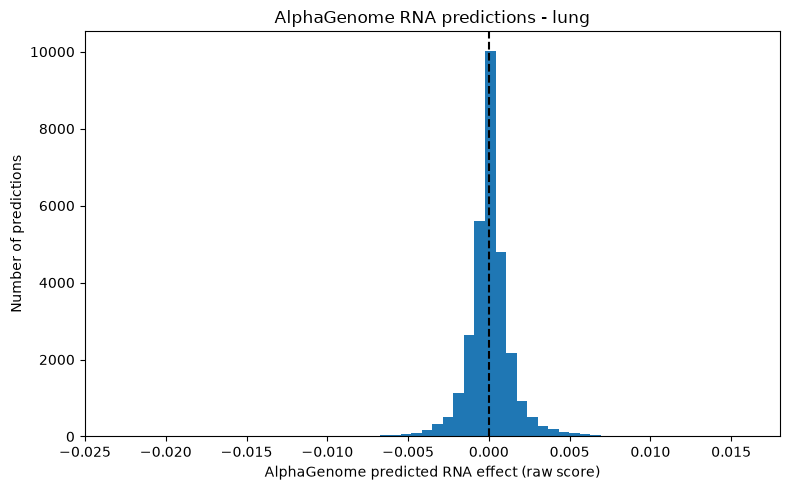


Top 20 variant–gene predictions:


,rsid,variant_key,target_gene,biosample_name,raw_score
28944,rs13334205,chr16:67547980:A>G,CARMIL2,lung microvascular endothelial cell,-0.023065
500913,rs2302643,chr2:64654095:G>A,SERTAD2,fibroblast of lung,-0.018789
139961,rs648116,chr11:114160034:T>C,ZBTB16,lung microvascular endothelial cell,0.016066
317457,rs3087631,chr16:2089126:A>T,PKD1,fibroblast of lung,0.015186
612880,rs3764906,chr2:42361055:T>C,RPS12P4,upper lobe of left lung,-0.014387
278587,rs8040086,chr15:40425476:A>T,PHGR1,upper lobe of left lung,0.013117
431068,rs504895,chr1:183246387:G>C,HMGN1P4,upper lobe of left lung,-0.012978
413611,rs1047981,chr1:183237438:G>A,HMGN1P4,bronchus fibroblast of lung,-0.012811
611025,rs3764907,chr2:42352931:T>A,RPS12P4,upper lobe of left lung,-0.011834
48839,rs7922621,chr10:80491788:C>G,TSPAN14,left lung,0.011761



Block 4 complete.


In [9]:
# ============================================================
# BLOCK 4 — ALPHAGENOME PREDICTION QC
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load saved predictions
scores = pd.read_csv(SCORE_FILE, sep="\t", low_memory=False)
status = pd.read_csv(STATUS_FILE, sep="\t")

scores = scores.drop_duplicates()

lung_scores = scores[
    scores["is_lung_track"].astype(str).str.lower().eq("true")
].copy()

# ------------------------------------------------------------
# 1. Check scoring completeness
# ------------------------------------------------------------

completed = set(
    status.loc[
        status["status"] == "success", "variant_key"
    ]
)

expected = set(variants["variant_key"])

print("=" * 55)
print("ALPHAGENOME PREDICTION QC")
print("=" * 55)

print("Input variants:", len(expected))
print("Successfully processed:", len(expected & completed))
print("Not successfully processed:", len(expected - completed))

print("\nPrediction coverage:")
print("Variants with target-gene scores:",
      scores["variant_key"].nunique())
print("Target genes:", scores["target_gene"].nunique())
print("Lung prediction rows:", len(lung_scores))

print(
    "Unique lung variant–gene pairs:",
    lung_scores[
        ["variant_key", "target_gene"]
    ].drop_duplicates().shape[0]
)

# ------------------------------------------------------------
# 2. Check missing values
# ------------------------------------------------------------

print("\nMissing values:")
display(
    scores[
        ["variant_key", "target_gene", "raw_score", "quantile_score"]
    ].isna().sum().to_frame("missing")
)

# ------------------------------------------------------------
# 3. Inspect lung biosamples
# ------------------------------------------------------------

print("\nLung-related biosamples:")
display(
    lung_scores["biosample_name"]
    .value_counts()
    .to_frame("prediction_rows")
)

# ------------------------------------------------------------
# 4. Plot distribution of AlphaGenome RNA effects
# ------------------------------------------------------------

lung_scores["raw_score"] = pd.to_numeric(
    lung_scores["raw_score"], errors="coerce"
)

plt.figure(figsize=(8, 5))
plt.hist(
    lung_scores["raw_score"].dropna(),
    bins=60
)
plt.axvline(0, linestyle="--", color="black")
plt.xlabel("AlphaGenome predicted RNA effect (raw score)")
plt.ylabel("Number of predictions")
plt.title("AlphaGenome RNA predictions - lung")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Inspect strongest predictions (exploration only)
# ------------------------------------------------------------

strongest = (
    lung_scores
    .assign(abs_score=lambda x: x["raw_score"].abs())
    .sort_values("abs_score", ascending=False)
    .drop_duplicates(["variant_key", "target_gene"])
)

print("\nTop 20 variant–gene predictions:")
display(
    strongest[
        [
            "rsid", "variant_key", "target_gene",
            "biosample_name", "raw_score"
        ]
    ].head(20)
)

print("\nBlock 4 complete.")

In [10]:
# ============================================================
# BLOCK 6 — ALPHAGENOME vs NATRI SINGLE-CELL eQTLs
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# 1. Load Natri eQTL results
# ------------------------------------------------------------

EQTL_FILE = Path(
    "/path/to/your/lung_sc_eQTL_Natri_2024/"
    "189_distal_loop_scEQTL_all_results.tsv"
)

assert EQTL_FILE.exists(), f"Missing: {EQTL_FILE}"

eqtl = pd.read_csv(
    EQTL_FILE,
    sep="\t",
    low_memory=False
)

# Load our newly generated AlphaGenome predictions
ag = pd.read_csv(
    LUNG_FILE,
    sep="\t",
    low_memory=False
)

print("=" * 60)
print("INPUT DATA")
print("=" * 60)

print("Natri eQTL rows:", len(eqtl))
print("AlphaGenome lung rows:", len(ag))

print("\nNatri columns:")
print(eqtl.columns.tolist())

print("\nNatri cell types:")
display(eqtl["cell_type"].value_counts())

# ------------------------------------------------------------
# 2. Prepare AlphaGenome variants
# ------------------------------------------------------------

ag = ag[
    ag["gene_name"] == ag["target_gene"]
].copy()

ag["chrom"] = (
    ag["chr"]
    .astype(str)
    .str.replace(r"^chr", "", regex=True, case=False)
    .str.upper()
)

ag["position"] = pd.to_numeric(
    ag["position"]
).astype(int)

ag["REF"] = ag["REF"].astype(str).str.upper()
ag["ALT"] = ag["ALT"].astype(str).str.upper()
ag["gene"] = ag["target_gene"].astype(str).str.strip()

ag["raw_score"] = pd.to_numeric(
    ag["raw_score"], errors="coerce"
)

# ------------------------------------------------------------
# 3. Prepare Natri eQTL variants
# ------------------------------------------------------------

# Natri SNP IDs follow the format:
# chromosome_position_REF_ALT
# e.g. 19_2232050_G_A

parts = eqtl["snp_id"].astype(str).str.extract(
    r"^(?P<chrom>[^_]+)_(?P<position>\d+)_(?P<REF>[ACGT]+)_(?P<ALT>[ACGT]+)$"
)

invalid = parts.isna().any(axis=1)

print("\nUnparseable Natri SNP IDs:", invalid.sum())

if invalid.any():
    display(eqtl.loc[invalid, ["snp_id"]].head(10))

eq = pd.concat(
    [
        eqtl.loc[~invalid].reset_index(drop=True),
        parts.loc[~invalid].reset_index(drop=True)
    ],
    axis=1
)

eq["chrom"] = (
    eq["chrom"]
    .astype(str)
    .str.replace(r"^chr", "", regex=True, case=False)
    .str.upper()
)

eq["position"] = eq["position"].astype(int)

eq["gene"] = (
    eq["target_gene_symbol"]
    .astype(str)
    .str.strip()
)

eq["beta"] = pd.to_numeric(
    eq["posterior_means"],
    errors="coerce"
)

eq["lfsr"] = pd.to_numeric(
    eq["lfsr"],
    errors="coerce"
)

# ------------------------------------------------------------
# 4. Define exact variant–gene matching
# ------------------------------------------------------------

KEY = ["chrom", "position", "REF", "ALT", "gene"]

ag_pairs = ag[KEY].drop_duplicates()
eq_pairs = eq[KEY].drop_duplicates()

matched_pairs = ag_pairs.merge(
    eq_pairs,
    on=KEY,
    how="inner"
)

print("\n" + "=" * 60)
print("EXACT VARIANT–GENE OVERLAP")
print("=" * 60)

print("AlphaGenome variant–gene pairs:", len(ag_pairs))
print("Natri variant–gene pairs:", len(eq_pairs))
print("Exact matched variant–gene pairs:", len(matched_pairs))

# ------------------------------------------------------------
# 5. Explore matches by Natri cell type
# ------------------------------------------------------------

matched_eqtl = eq.merge(
    matched_pairs,
    on=KEY,
    how="inner"
)

print("\nMatched Natri observations:", len(matched_eqtl))

if not matched_eqtl.empty:

    print("\nMatches by cell type:")

    display(
        matched_eqtl.groupby("cell_type")
        .agg(
            observations=("snp_id", "size"),
            unique_variants=("snp_id", "nunique"),
            unique_genes=("gene", "nunique"),
            lfsr_le_020=("lfsr", lambda x: (x <= 0.20).sum())
        )
        .sort_values("observations", ascending=False)
    )

    print("\nMatched variant–gene examples:")

    display(
        matched_eqtl[
            [
                "snp_rsid",
                "snp_id",
                "gene",
                "cell_type",
                "beta",
                "lfsr"
            ]
        ]
        .drop_duplicates()
        .sort_values("lfsr")
        .head(30)
    )

# ------------------------------------------------------------
# 6. Identify unmatched AlphaGenome predictions
# ------------------------------------------------------------

unmatched = ag_pairs.merge(
    eq_pairs,
    on=KEY,
    how="left",
    indicator=True
)

unmatched = unmatched[
    unmatched["_merge"] == "left_only"
].drop(columns="_merge")

print("\nAlphaGenome pairs without exact Natri match:", len(unmatched))

print("\nBlock 6 complete.")

INPUT DATA
Natri eQTL rows: 6216
AlphaGenome lung rows: 29955

Natri columns:
['loop_id', 'source', 'chr1', 'x1', 'x2', 'chr2', 'y1', 'y2', 'regulatory_direction', 'relationship', 'snp_anchor', 'gene_anchor', 'snp_rsid', 'target_gene_symbol', 'diff_HiC_label_fuzzy30kb', 'feature_id', 'snp_id', 'posterior_means', 'sds', 'lfsr', 'cell_type', 'eqtl_status']

Natri cell types:


cell_type
endothelial_Lymphatic                    126
endothelial_Systemicvenous               126
endothelial_aCap                         126
endothelial_arteriole                    126
endothelial_gCap                         126
endothelial_venule                       126
epithelial_AT1                           126
epithelial_AT2                           126
epithelial_Basal                         126
epithelial_Ciliated                      126
epithelial_DifferentiatingCiliated       126
epithelial_KRT5-KRT17+                   126
epithelial_Proliferating                 126
epithelial_Secretory-SCGB1A1+MUC5B+      126
epithelial_Secretory-SCGB1A1+SCGB3A2+    126
epithelial_Secretory-SCGB3A2+            126
epithelial_TransitionalAT2               126
immune_Alveolarmacrophage                126
immune_Bcells                            126
immune_CD4                               126
immune_CD8NKT                            126
immune_Inflammatorymonocyte              126



Unparseable Natri SNP IDs: 1428


,snp_id
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
5,NaN
6,NaN
7,NaN
8,NaN
9,NaN



EXACT VARIANT–GENE OVERLAP
AlphaGenome variant–gene pairs: 1976
Natri variant–gene pairs: 72
Exact matched variant–gene pairs: 61

Matched Natri observations: 3572

Matches by cell type:


,observations,unique_variants,unique_genes,lfsr_le_020
cell_type,,,,
endothelial_Lymphatic,94,52,45,4
endothelial_Systemicvenous,94,52,45,6
endothelial_aCap,94,52,45,5
endothelial_arteriole,94,52,45,6
endothelial_gCap,94,52,45,2
endothelial_venule,94,52,45,5
epithelial_AT1,94,52,45,5
epithelial_AT2,94,52,45,4
epithelial_Basal,94,52,45,6



Matched variant–gene examples:


,snp_rsid,snp_id,gene,cell_type,beta,lfsr
330,rs721917,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB1A1+MUC5B+,-0.079021,0.009796
328,rs721917,10_79946568_A_G,SFTPA2,epithelial_Proliferating,-0.072153,0.010911
334,rs721917,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB3A2+,-0.074409,0.012165
335,rs721917,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB3A2+,-0.074409,0.012165
332,rs721917,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB1A1+SCGB3A2+,-0.067372,0.015032
336,rs721917,10_79946568_A_G,SFTPA2,epithelial_TransitionalAT2,-0.062765,0.016783
320,rs721917,10_79946568_A_G,SFTPA2,epithelial_Basal,-0.062619,0.017906
324,rs721917,10_79946568_A_G,SFTPA2,epithelial_DifferentiatingCiliated,-0.068841,0.018074
318,rs721917,10_79946568_A_G,SFTPA2,epithelial_AT2,-0.063633,0.021917
310,rs721917,10_79946568_A_G,SFTPA2,endothelial_arteriole,-0.059223,0.023569



AlphaGenome pairs without exact Natri match: 1915

Block 6 complete.


In [24]:
# ============================================================
# BLOCK 7 — PREPARE MATCHED NATRI eQTLs
# ============================================================

KEY = ["chrom", "position", "REF", "ALT", "gene"]
EQTL_KEY = KEY + ["cell_type"]

# Retrieve Natri observations for our matched pairs
eq_matched = eq.merge(
    matched_pairs,
    on=KEY,
    how="inner"
).copy()

eq_matched["beta"] = pd.to_numeric(
    eq_matched["beta"], errors="coerce"
)

eq_matched["lfsr"] = pd.to_numeric(
    eq_matched["lfsr"], errors="coerce"
)

eq_matched["sds"] = pd.to_numeric(
    eq_matched["sds"], errors="coerce"
)

# Identify groups with differences in reported measurements
conflicts = (
    eq_matched.groupby(EQTL_KEY, dropna=False)
    .agg(
        n_beta=("beta", lambda x: x.dropna().nunique()),
        n_lfsr=("lfsr", lambda x: x.dropna().nunique())
    )
    .reset_index()
)

conflicts = conflicts[
    (conflicts["n_beta"] > 1) |
    (conflicts["n_lfsr"] > 1)
]

print("Matched eQTL rows:", len(eq_matched))
print("Groups with apparent differences:", len(conflicts))

Matched eQTL rows: 3572
Groups with apparent differences: 220


In [12]:
# ============================================================
# BLOCK 7A — INVESTIGATE CONFLICTING NATRI eQTL RECORDS
# ============================================================

print("Variant–gene–cell-type combinations with conflicts:",
      len(conflicts))

# Retrieve all records belonging to conflicting groups
conflict_rows = eq_matched.merge(
    conflicts[EQTL_KEY],
    on=EQTL_KEY,
    how="inner"
)

# Show whether conflicts involve different effect sizes,
# uncertainties, SNP identifiers, or source annotations
columns = [
    "snp_rsid", "snp_id", "gene", "cell_type",
    "beta", "sds", "lfsr",
    "loop_id", "source", "feature_id",
    "eqtl_status"
]

columns = [c for c in columns if c in conflict_rows.columns]

display(
    conflict_rows[columns]
    .sort_values(["gene", "cell_type", "snp_id"])
    .head(40)
)

print("\nConflicting groups by gene:")
display(
    conflicts.groupby("gene")
    .size()
    .sort_values(ascending=False)
    .to_frame("conflicting_groups")
)

print("\nNumber of distinct measurements per group:")
display(
    conflicts[["n_beta", "n_lfsr"]]
    .value_counts()
    .to_frame("groups")
)

print("\nExample: first conflicting group")

first = conflicts.iloc[0]

example = conflict_rows.copy()

for col in EQTL_KEY:
    example = example[
        example[col] == first[col]
    ]

display(example[columns])

Variant–gene–cell-type combinations with conflicts: 220


,snp_rsid,snp_id,gene,cell_type,beta,sds,lfsr,loop_id,source,feature_id,eqtl_status
266,rs740404,19_2232050_G_A,AP3D1,epithelial_Proliferating,0.054057,0.042665,0.149806,5114,both,ENSG00000065000,tested_not_significant
267,rs740404,19_2232050_G_A,AP3D1,epithelial_Proliferating,0.054057,0.042665,0.149806,5114,both,ENSG00000065000,tested_not_significant
268,rs740404,19_2232050_G_A,AP3D1,mesenchymal_AlveolarFB,0.036942,0.038204,0.182414,5114,both,ENSG00000065000,tested_not_significant
269,rs740404,19_2232050_G_A,AP3D1,mesenchymal_AlveolarFB,0.036942,0.038204,0.182414,5114,both,ENSG00000065000,tested_not_significant
82,rs11826069,11_35404496_G_A,APIP,endothelial_Systemicvenous,0.001739,0.022223,0.816368,1932,COPD,ENSG00000149089,tested_not_significant
83,rs11826069,11_35404496_G_A,APIP,endothelial_Systemicvenous,0.001739,0.022223,0.816368,1932,COPD,ENSG00000149089,tested_not_significant
34,rs10501137,11_35408741_T_C,APIP,endothelial_Systemicvenous,0.002747,0.023623,0.742652,1932,COPD,ENSG00000149089,tested_not_significant
35,rs10501137,11_35408741_T_C,APIP,endothelial_Systemicvenous,0.002747,0.023623,0.742652,1932,COPD,ENSG00000149089,tested_not_significant
36,rs10501137,11_35408741_T_C,APIP,endothelial_aCap,0.002985,0.020025,0.743996,1932,COPD,ENSG00000149089,tested_not_significant
37,rs10501137,11_35408741_T_C,APIP,endothelial_aCap,0.002985,0.020025,0.743996,1932,COPD,ENSG00000149089,tested_not_significant



Conflicting groups by gene:


,conflicting_groups
gene,
APIP,43
CEBPD,40
CFAP20,38
IRF1,34
SCGB1A1,23
CCDC33,7
TSPAN14,7
SFTPA2,6
PEBP4,5



Number of distinct measurements per group:


groups
n_beta n_lfsr        
1      2          159
2      1           31
       2           30


Example: first conflicting group


,snp_rsid,snp_id,gene,cell_type,beta,sds,lfsr,loop_id,source,feature_id,eqtl_status
0,rs11586916,1_154279038_T_C,CFAP141,epithelial_DifferentiatingCiliated,-0.013349,0.02903,0.600092,713,HD,ENSG00000163263,tested_not_significant
1,rs11586916,1_154279038_T_C,CFAP141,epithelial_DifferentiatingCiliated,-0.013349,0.02903,0.600092,713,HD,ENSG00000163263,tested_not_significant


In [13]:
# ============================================================
# BLOCK 7B — QUANTIFY eQTL DUPLICATE DIFFERENCES
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

KEY = ["chrom", "position", "REF", "ALT", "gene"]
EQTL_KEY = KEY + ["cell_type"]

# Calculate numerical ranges within each duplicate group
duplicate_qc = (
    eq_matched.groupby(EQTL_KEY, dropna=False)
    .agg(
        n_rows=("beta", "size"),
        beta_min=("beta", "min"),
        beta_max=("beta", "max"),
        lfsr_min=("lfsr", "min"),
        lfsr_max=("lfsr", "max"),
        sd_min=("sds", "min"),
        sd_max=("sds", "max")
    )
    .reset_index()
)

duplicate_qc["beta_diff"] = (
    duplicate_qc["beta_max"] - duplicate_qc["beta_min"]
).abs()

duplicate_qc["lfsr_diff"] = (
    duplicate_qc["lfsr_max"] - duplicate_qc["lfsr_min"]
).abs()

duplicate_qc["sd_diff"] = (
    duplicate_qc["sd_max"] - duplicate_qc["sd_min"]
).abs()

# Difference tolerance for this diagnostic
TOL = 1e-7

duplicate_qc["material_difference"] = (
    (duplicate_qc["beta_diff"] > TOL) |
    (duplicate_qc["lfsr_diff"] > TOL) |
    (duplicate_qc["sd_diff"] > TOL)
)

repeated = duplicate_qc[
    duplicate_qc["n_rows"] > 1
].copy()

print("=" * 60)
print("NATRI DUPLICATE QUALITY CONTROL")
print("=" * 60)

print("Total unique variant–gene–cell-type groups:",
      len(duplicate_qc))

print("Groups with repeated records:", len(repeated))

print("Groups with numerical differences > 1e-7:",
      repeated["material_difference"].sum())

print("\nMaximum differences:")
print("Beta:", repeated["beta_diff"].max())
print("LFSR:", repeated["lfsr_diff"].max())
print("SD:", repeated["sd_diff"].max())

print("\nDifference distributions:")
display(
    repeated[
        ["beta_diff", "lfsr_diff", "sd_diff"]
    ].describe()
)

print("\nGroups with largest differences:")
display(
    repeated.sort_values(
        ["beta_diff", "lfsr_diff"],
        ascending=False
    )[
        [
            "gene", "cell_type", "n_rows",
            "beta_diff", "lfsr_diff",
            "sd_diff"
        ]
    ].head(20)
)

# Do not silently discard genuinely different measurements
if repeated["material_difference"].any():

    print(
        "\nWARNING: Some duplicate groups have meaningful "
        "numerical differences. Inspect these before deduplication."
    )

else:

    print(
        "\nAll repeated measurements agree within tolerance."
    )

    # Safe to continue with one row per association and cell type
    eq_clean = (
        eq_matched
        .drop_duplicates(EQTL_KEY)
        .reset_index(drop=True)
    )

    print("\nCleaned observations:", len(eq_clean))
    print("Unique variant–gene pairs:",
          len(eq_clean[KEY].drop_duplicates()))
    print("Cell types:", eq_clean["cell_type"].nunique())

NATRI DUPLICATE QUALITY CONTROL
Total unique variant–gene–cell-type groups: 2318
Groups with repeated records: 1178
Groups with numerical differences > 1e-7: 0

Maximum differences:
Beta: 2.0122792321330962e-16
LFSR: 1.1102230246251565e-15
SD: 2.0122792321330962e-16

Difference distributions:


,beta_diff,lfsr_diff,sd_diff
count,1.178000e+03,1.178000e+03,1.178000e+03
mean,4.505607e-18,1.566847e-16,7.041976e-18
std,2.113026e-17,3.630139e-16,2.623685e-17
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00,0.000000e+00
75%,0.000000e+00,0.000000e+00,0.000000e+00
max,2.012279e-16,1.110223e-15,2.012279e-16



Groups with largest differences:


,gene,cell_type,n_rows,beta_diff,lfsr_diff,sd_diff
2018,IRF1,endothelial_gCap,2,2.012279e-16,9.992007e-16,1.942890e-16
2304,CEBPD,immune_Monocyte,2,1.040834e-16,9.992007e-16,0.000000e+00
2023,IRF1,epithelial_Ciliated,2,1.006140e-16,1.110223e-15,0.000000e+00
451,APIP,mesenchymal_AdventitialFB,2,1.006140e-16,9.992007e-16,9.714451e-17
481,APIP,immune_Monocyte-derivedmacrophage,2,1.006140e-16,9.992007e-16,1.006140e-16
517,SCGB1A1,immune_Mast,2,1.006140e-16,9.992007e-16,1.006140e-16
524,SCGB1A1,immune_cDC2,2,1.006140e-16,9.992007e-16,0.000000e+00
1025,CFAP20,mesenchymal_SMC,2,1.006140e-16,9.992007e-16,1.040834e-16
2015,IRF1,endothelial_Systemicvenous,2,1.006140e-16,9.992007e-16,0.000000e+00
2033,IRF1,immune_CD4,2,1.006140e-16,9.992007e-16,0.000000e+00



All repeated measurements agree within tolerance.

Cleaned observations: 2318
Unique variant–gene pairs: 61
Cell types: 38


In [14]:
# Save cleaned Natri eQTL observations
eq_clean.to_csv(
    OUT / "Natri_matched_eQTL_clean.tsv",
    sep="\t",
    index=False
)

# Save unique matched variant–gene pairs
matched_pairs.to_csv(
    OUT / "AlphaGenome_Natri_matched_variant_gene_pairs.tsv",
    sep="\t",
    index=False
)

print("Saved cleaned Natri eQTLs and 61 matched variant–gene pairs.")

Saved cleaned Natri eQTLs and 61 matched variant–gene pairs.


In [25]:
# ============================================================
# BLOCK 8 — SELECT ADULT BULK LUNG ALPHAGENOME TRACK
# ============================================================

KEY = ["chrom", "position", "REF", "ALT", "gene"]

SELECTED_TRACK = "UBERON:0002048 polyA plus RNA-seq"

# Match AlphaGenome predictions to Natri pairs
ag_matched = ag.merge(
    matched_pairs,
    on=KEY,
    how="inner"
).copy()

ag_matched["raw_score"] = pd.to_numeric(
    ag_matched["raw_score"], errors="coerce"
)

# Select adult bulk lung RNA-seq predictions
ag_selected = ag_matched[
    (ag_matched["track_name"] == SELECTED_TRACK) &
    (ag_matched["biosample_name"] == "lung") &
    (ag_matched["biosample_life_stage"] == "adult")
].copy()

# Check repeated scores for the same variant–gene pair
qc = (
    ag_selected.groupby(KEY)
    .agg(
        n_rows=("raw_score", "size"),
        min_score=("raw_score", "min"),
        max_score=("raw_score", "max"),
        n_missing=("raw_score", lambda x: x.isna().sum())
    )
    .reset_index()
)

qc["score_difference"] = (
    qc["max_score"] - qc["min_score"]
).abs()

print("Selected track:", SELECTED_TRACK)
print("Adult lung prediction rows:", len(ag_selected))
print("Unique variant–gene pairs:", len(qc))
print(
    "Pairs with different scores:",
    (qc["score_difference"] > 1e-10).sum()
)

display(qc["n_rows"].value_counts().sort_index())

Selected track: UBERON:0002048 polyA plus RNA-seq
Adult lung prediction rows: 62
Unique variant–gene pairs: 61
Pairs with different scores: 1


n_rows
1    60
2     1
Name: count, dtype: int64

In [21]:
# ============================================================
# BLOCK 8A — INVESTIGATE DIFFERENT ALPHAGENOME SCORES
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

KEY = ["chrom", "position", "REF", "ALT", "gene"]

print("=" * 60)
print("ALPHAGENOME ADULT LUNG SCORE DIAGNOSTICS")
print("=" * 60)

print("Adult lung prediction rows:", len(ag_selected))
print("Unique variant–gene pairs:", len(qc))

different = qc[
    qc["score_difference"] > 1e-10
].copy()

print("Pairs with different scores:", len(different))
print("Maximum score difference:", qc["score_difference"].max())

print("\nNumber of rows per pair:")
display(qc["n_rows"].value_counts().sort_index())

print("\nPairs with largest score differences:")
display(
    different.sort_values(
        "score_difference", ascending=False
    ).head(15)
)

# Show the original prediction records for the most
# discrepant variant–gene pair.
if not different.empty:

    example = different.sort_values(
        "score_difference", ascending=False
    ).iloc[0]

    example_rows = ag_selected.copy()

    for col in KEY:
        example_rows = example_rows[
            example_rows[col] == example[col]
        ]

    print("\nOriginal records for most discrepant pair:")

    relevant_cols = [
        "rsid",
        "variant_key",
        "gene_name",
        "target_gene",
        "track_name",
        "biosample_name",
        "biosample_life_stage",
        "raw_score",
        "quantile_score",
        "window_label",
        "sequence_length",
        "scored_interval",
        "strand"
    ]

    relevant_cols = [
        c for c in relevant_cols
        if c in example_rows.columns
    ]

    display(example_rows[relevant_cols])

print("\nAll available columns:")
print(ag_selected.columns.tolist())

ALPHAGENOME ADULT LUNG SCORE DIAGNOSTICS
Adult lung prediction rows: 62
Unique variant–gene pairs: 61
Pairs with different scores: 1
Maximum score difference: 6.353855999999996e-05

Number of rows per pair:


n_rows
1    60
2     1
Name: count, dtype: int64


Pairs with largest score differences:


,chrom,position,REF,ALT,gene,n_rows,min_score,max_score,n_missing,score_difference
18,14,36217398,T,C,SFTA3,2,-0.000907,-0.000843,0,0.000064



Original records for most discrepant pair:


,rsid,variant_key,gene_name,target_gene,track_name,biosample_name,biosample_life_stage,raw_score,quantile_score,window_label,sequence_length,scored_interval
181,rs10132289,chr14:36217398:T>C,SFTA3,SFTA3,UBERON:0002048 polyA plus RNA-seq,lung,adult,-0.000843,-0.600902,CENTER,1Mb,chr14:35693110-36741686:.
182,rs10132289,chr14:36217398:T>C,SFTA3,SFTA3,UBERON:0002048 polyA plus RNA-seq,lung,adult,-0.000907,-0.622109,CENTER,1Mb,chr14:35693110-36741686:.



All available columns:
['scored_interval', 'gene_id', 'gene_name', 'gene_type', 'gene_strand', 'junction_Start', 'junction_End', 'output_type', 'variant_scorer', 'track_name', 'track_strand', 'Assay title', 'ontology_curie', 'biosample_name', 'biosample_type', 'biosample_life_stage', 'gtex_tissue', 'data_source', 'endedness', 'genetically_modified', 'raw_score', 'quantile_score', 'variant_key', 'rsid', 'chr', 'position', 'REF', 'ALT', 'target_gene', 'is_lung_track', 'window_label', 'sequence_length', 'chrom', 'gene']


AlphaGenome pairs retained: 60
Ambiguous pairs excluded: 1

MATCHED BENCHMARK DATASET
Matched observations: 2280
Unique SNP–gene pairs: 60
Natri cell types: 38

Natri eQTL evidence:

LFSR <= 0.2
Cell-type observations: 130
Unique SNP–gene pairs: 5

LFSR <= 0.05
Cell-type observations: 28
Unique SNP–gene pairs: 1

Natri eQTL evidence by cell type:


,total_pairs,significant_020,significant_005
cell_type,,,
immune_Proliferating,60,5,1
immune_Monocyte,60,5,1
immune_Monocyte-derivedmacrophage,60,5,1
immune_Alveolarmacrophage,60,5,1
immune_CD8NKT,60,5,1
immune_CD4,60,5,1
immune_cDC2,60,4,1
immune_moDC,60,4,1
immune_NK,60,4,1



Strongest Natri eQTL associations:


,snp_id,gene,cell_type,beta,lfsr,raw_score,natri_direction,ag_direction
203,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB1A1+MUC5B+,-0.079021,0.009796,-0.000154,Negative,Negative
202,10_79946568_A_G,SFTPA2,epithelial_Proliferating,-0.072153,0.010911,-0.000154,Negative,Negative
205,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB3A2+,-0.074409,0.012165,-0.000154,Negative,Negative
204,10_79946568_A_G,SFTPA2,epithelial_Secretory-SCGB1A1+SCGB3A2+,-0.067372,0.015032,-0.000154,Negative,Negative
206,10_79946568_A_G,SFTPA2,epithelial_TransitionalAT2,-0.062765,0.016783,-0.000154,Negative,Negative
198,10_79946568_A_G,SFTPA2,epithelial_Basal,-0.062619,0.017906,-0.000154,Negative,Negative
200,10_79946568_A_G,SFTPA2,epithelial_DifferentiatingCiliated,-0.068841,0.018074,-0.000154,Negative,Negative
197,10_79946568_A_G,SFTPA2,epithelial_AT2,-0.063633,0.021917,-0.000154,Negative,Negative
193,10_79946568_A_G,SFTPA2,endothelial_arteriole,-0.059223,0.023569,-0.000154,Negative,Negative
196,10_79946568_A_G,SFTPA2,epithelial_AT1,-0.056670,0.025760,-0.000154,Negative,Negative


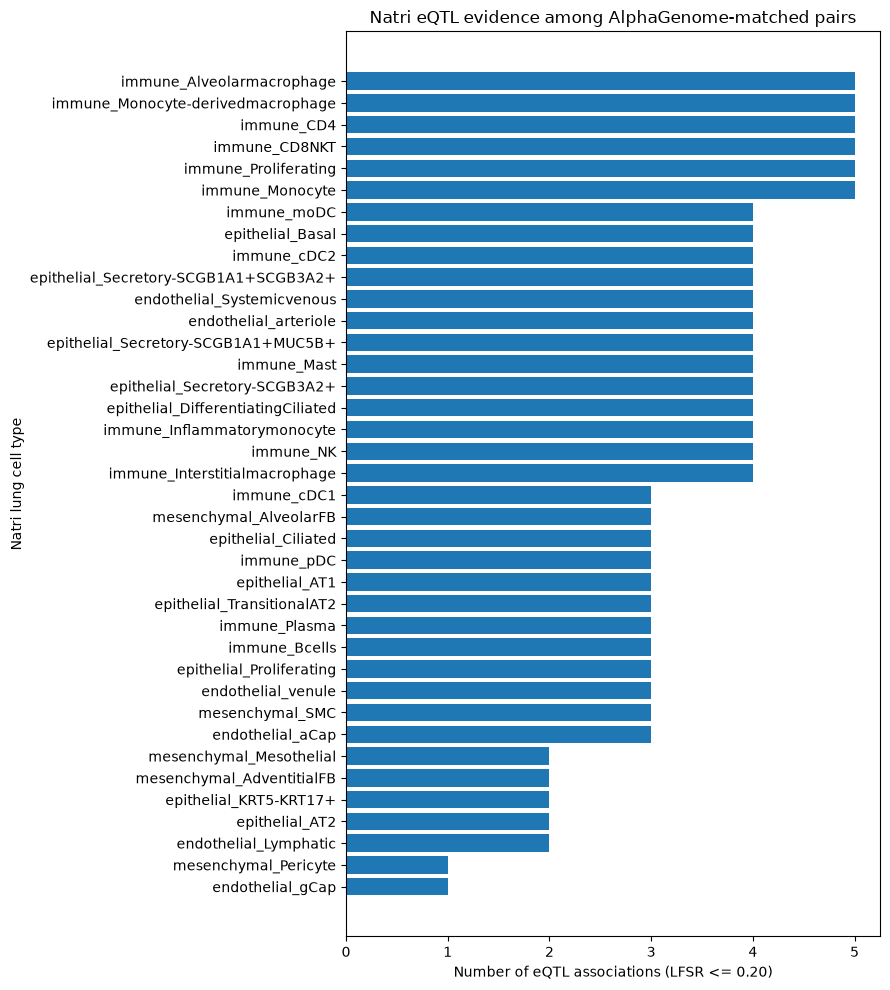


Block 9 complete.


In [22]:
# ============================================================
# BLOCK 9 — ALPHAGENOME vs NATRI eQTL COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

KEY = ["chrom", "position", "REF", "ALT", "gene"]

# ------------------------------------------------------------
# 1. Keep AlphaGenome pairs with one unambiguous lung score
# ------------------------------------------------------------

# ag_selected: adult lung predictions from Block 8
# eq_clean: cleaned Natri eQTLs from Block 7B

assert "ag_selected" in globals()
assert "eq_clean" in globals()

ag_counts = ag_selected.groupby(KEY).size()

valid_keys = (
    ag_counts[ag_counts == 1]
    .reset_index()[KEY]
)

ag_final = ag_selected.merge(
    valid_keys,
    on=KEY,
    how="inner"
).copy()

print("AlphaGenome pairs retained:", len(ag_final))
print("Ambiguous pairs excluded:", (ag_counts > 1).sum())

assert len(ag_final) == 60

# ------------------------------------------------------------
# 2. Match AlphaGenome predictions to Natri eQTLs
# ------------------------------------------------------------

ag_final["raw_score"] = pd.to_numeric(
    ag_final["raw_score"], errors="coerce"
)

comparison = eq_clean.merge(
    ag_final[
        KEY + ["rsid", "raw_score", "quantile_score"]
    ],
    on=KEY,
    how="inner",
    validate="many_to_one",
    suffixes=("_natri", "_alphagenome")
)

comparison["beta"] = pd.to_numeric(
    comparison["beta"], errors="coerce"
)

comparison["lfsr"] = pd.to_numeric(
    comparison["lfsr"], errors="coerce"
)

comparison = comparison.dropna(
    subset=["beta", "lfsr", "raw_score"]
)

print("\n" + "=" * 60)
print("MATCHED BENCHMARK DATASET")
print("=" * 60)

print("Matched observations:", len(comparison))
print("Unique SNP–gene pairs:",
      len(comparison[KEY].drop_duplicates()))
print("Natri cell types:", comparison["cell_type"].nunique())

# ------------------------------------------------------------
# 3. Identify eQTLs with strong directional evidence
# ------------------------------------------------------------

comparison["significant_020"] = (
    comparison["lfsr"] <= 0.20
)

comparison["significant_005"] = (
    comparison["lfsr"] <= 0.05
)

print("\nNatri eQTL evidence:")

for threshold in [0.20, 0.05]:

    subset = comparison[
        comparison["lfsr"] <= threshold
    ]

    print(f"\nLFSR <= {threshold}")
    print("Cell-type observations:", len(subset))
    print(
        "Unique SNP–gene pairs:",
        len(subset[KEY].drop_duplicates())
    )

# ------------------------------------------------------------
# 4. Summarize eQTL evidence by lung cell type
# ------------------------------------------------------------

cell_summary = (
    comparison.groupby("cell_type")
    .agg(
        total_pairs=("gene", "size"),
        significant_020=("significant_020", "sum"),
        significant_005=("significant_005", "sum")
    )
    .sort_values("significant_020", ascending=False)
)

print("\nNatri eQTL evidence by cell type:")
display(cell_summary)

# ------------------------------------------------------------
# 5. Inspect AlphaGenome vs Natri for strong eQTLs
# ------------------------------------------------------------

strong_eqtl = comparison[
    comparison["lfsr"] <= 0.20
].copy()

strong_eqtl["ag_direction"] = np.where(
    strong_eqtl["raw_score"] > 0,
    "Positive",
    np.where(
        strong_eqtl["raw_score"] < 0,
        "Negative",
        "Zero"
    )
)

strong_eqtl["natri_direction"] = np.where(
    strong_eqtl["beta"] > 0,
    "Positive",
    np.where(
        strong_eqtl["beta"] < 0,
        "Negative",
        "Zero"
    )
)

print("\nStrongest Natri eQTL associations:")
display(
    strong_eqtl[
        [
            "snp_id",
            "gene",
            "cell_type",
            "beta",
            "lfsr",
            "raw_score",
            "natri_direction",
            "ag_direction"
        ]
    ]
    .sort_values("lfsr")
    .head(30)
)

# ------------------------------------------------------------
# 6. Plot eQTL evidence across cell types
# ------------------------------------------------------------

plot_data = (
    cell_summary["significant_020"]
    .sort_values()
)

plt.figure(figsize=(9, 10))

plt.barh(
    plot_data.index,
    plot_data.values
)

plt.xlabel("Number of eQTL associations (LFSR <= 0.20)")
plt.ylabel("Natri lung cell type")
plt.title("Natri eQTL evidence among AlphaGenome-matched pairs")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Save the comparison dataset
# ------------------------------------------------------------

COMPARISON_FILE = (
    OUT / "AlphaGenome_Natri_adult_lung_comparison.tsv"
)

comparison.to_csv(
    COMPARISON_FILE,
    sep="\t",
    index=False
)

print("\nSaved:", COMPARISON_FILE)
print("\nBlock 9 complete.")

In [23]:
# ============================================================
# BLOCK 10 — ALLELE VALIDATION AND SUPPORTED eQTL PAIRS
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

KEY = ["chrom", "position", "REF", "ALT", "gene"]

benchmark = comparison.copy()

for col in ["raw_score", "beta", "lfsr"]:
    benchmark[col] = pd.to_numeric(
        benchmark[col], errors="coerce"
    )

assert not benchmark[KEY].isna().any().any()
assert benchmark[["raw_score", "beta", "lfsr"]].notna().any(axis=1).all()

# Check that Natri SNP identifiers match our genomic alleles
parts = benchmark["snp_id"].astype(str).str.extract(
    r"^(?:chr)?([^_]+)_(\d+)_([ACGT]+)_([ACGT]+)$"
)

valid_ids = parts.notna().all(axis=1)

assert valid_ids.all(), "Unparseable SNP IDs remain"

same_alleles = (
    (parts[0].str.upper().values == benchmark["chrom"].astype(str).values) &
    (parts[1].astype(int).values == benchmark["position"].astype(int).values) &
    (parts[2].values == benchmark["REF"].values) &
    (parts[3].values == benchmark["ALT"].values)
)

print("Variant identifiers matching REF/ALT:",
      same_alleles.sum(), "/", len(benchmark))

assert same_alleles.all(), "Variant allele mismatch"

# Identify distinct eQTL-supported pairs
supported = benchmark[
    benchmark["lfsr"] <= 0.20
].copy()

pair_summary = (
    supported.groupby(KEY, as_index=False)
    .agg(
        snp_id=("snp_id", "first"),
        ag_score=("raw_score", "first"),
        min_lfsr=("lfsr", "min"),
        n_supported_cell_types=("cell_type", "nunique"),
        mean_eqtl_beta=("beta", "mean"),
        min_eqtl_beta=("beta", "min"),
        max_eqtl_beta=("beta", "max")
    )
    .sort_values("min_lfsr")
)

print("\nTotal matched SNP–gene pairs:",
      len(benchmark[KEY].drop_duplicates()))

print("eQTL-supported pairs (LFSR <= 0.20):",
      len(pair_summary))

display(pair_summary)

# Allele convention must be established using the original
# Natri genotype coding / data-processing documentation.
NATRI_EFFECT_ALLELE = None

print("\nAllele convention: NOT YET VERIFIED")
print("Next requirement: establish whether beta is ALT- or REF-oriented.")

Variant identifiers matching REF/ALT: 2280 / 2280

Total matched SNP–gene pairs: 60
eQTL-supported pairs (LFSR <= 0.20): 5


,chrom,position,REF,ALT,gene,snp_id,ag_score,min_lfsr,n_supported_cell_types,mean_eqtl_beta,min_eqtl_beta,max_eqtl_beta
1,10,79946568,A,G,SFTPA2,10_79946568_A_G,-0.000154,0.009796,38,-0.055769,-0.079021,-0.032956
0,1,201445972,C,T,CSRP1,1_201445972_C_T,-0.000404,0.100294,25,0.036405,0.024050,0.054778
3,22,49935414,T,C,TRABD,22_49935414_T_C,0.000623,0.106468,27,-0.054573,-0.083795,-0.037129
2,19,2232050,G,A,AP3D1,19_2232050_G_A,0.000152,0.126989,34,0.048459,0.033921,0.063512
4,22,49949496,T,C,TRABD,22_49949496_T_C,0.000046,0.185176,6,-0.058782,-0.063681,-0.054190



Allele convention: NOT YET VERIFIED
Next requirement: establish whether beta is ALT- or REF-oriented.
